# MH6805 | Group 30 | CHEN WEIQI | G2605197A
## Tree-Based Ensembles and PageValues Robustness

**Algorithms:** Random Forest (bagging) and LightGBM (gradient-boosted decision trees)  
**Research target:** `Revenue=True` (purchase); main predictors exclude `PageValues`.  
**Training seed:** **6805** (used for NumPy, CV shuffling, model fitting, hyperparameter search and permutations).

### Research questions
1. How accurately can bagged and boosted trees identify purchasing sessions using features excluding `PageValues`?
2. Does LightGBM outperform Random Forest for minority-class detection on the **same untouched held-out test data**?
3. How much does including `PageValues` change predictive performance, and can such an advantage be considered deployable without an information-timing audit?
4. Which variables matter in an interpretable, held-out, permutation-based assessment?

## 1 | Imports, reproducibility, and data loading

In [1]:
from pathlib import Path
import warnings
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss,
    confusion_matrix, precision_recall_curve, roc_curve, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from lightgbm import LGBMClassifier
import sklearn, lightgbm

warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names, but LGBMClassifier was fitted with feature names",
    category=UserWarning
)

SEED = 6805
np.random.seed(SEED)
random.seed(SEED)

TRAIN_FILENAME = "online_shoppers_train_fixed.csv"
TEST_FILENAME = "online_shoppers_test_fixed.csv"

def load_fixed_data():
    # Prefer the original supplied ZIP so the notebook can be moved alongside it.
    bases = [Path.cwd(), Path.cwd() / "ML_data", Path.cwd() / "data", Path('/mnt/data')]
    for base in bases:
        train_path, test_path = base / TRAIN_FILENAME, base / TEST_FILENAME
        if train_path.is_file() and test_path.is_file():
            return pd.read_csv(train_path), pd.read_csv(test_path), str(base)
        zip_path = base / "ML_data.zip"
        if zip_path.is_file():
            with zipfile.ZipFile(zip_path) as z:
                tr = next((n for n in z.namelist() if n.endswith(TRAIN_FILENAME)), None)
                te = next((n for n in z.namelist() if n.endswith(TEST_FILENAME)), None)
                if tr and te:
                    with z.open(tr) as f: train = pd.read_csv(f)
                    with z.open(te) as f: test = pd.read_csv(f)
                    return train, test, str(zip_path)
    raise FileNotFoundError(
        "Put ML_data.zip or both fixed CSVs in the notebook folder (or ML_data/)."
    )

train_raw, test_raw, data_source = load_fixed_data()
print("Data source:", data_source)
print("sklearn:", sklearn.__version__, "| lightgbm:", lightgbm.__version__)
print("Train / test:", train_raw.shape, test_raw.shape)
print("Training seed:", SEED)
print("Train purchase rate:", round(train_raw.Revenue.astype(int).mean(), 4))
print("Test purchase rate:", round(test_raw.Revenue.astype(int).mean(), 4))
display(train_raw.head(3))

Data source: c:\Users\Welkin\OneDrive - HKUST Connect\Desktop\NTU_academic\semester1\6805\group project\coding
sklearn: 1.6.1 | lightgbm: 4.6.0
Train / test: (9764, 18) (2441, 18)
Training seed: 6805
Train purchase rate: 0.1563
Test purchase rate: 0.1565


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False


## 2 | Integrity checks and shared feature definitions

`Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, and `Weekend` are categorical. The remaining features are numeric. Categorical IDs are **not** treated as continuous or ordinal distances. Importantly, the two fixed files are used without further row deletion or shuffling.

Potential target leakage through `PageValues` is **a hypothesis, not an established fact**. Feature availability relative to a chosen prediction timestamp must be independently established.

In [2]:
TARGET = "Revenue"
CAT_COLS = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
NUM_COLS = [c for c in train_raw.columns if c not in CAT_COLS + [TARGET]]
assert list(train_raw.columns) == list(test_raw.columns), "Train/test schema mismatch"
assert train_raw[TARGET].notna().all() and test_raw[TARGET].notna().all()
assert len(train_raw) == 9764 and len(test_raw) == 2441, "Unexpected split sizes"
assert len(CAT_COLS) == 7 and len(NUM_COLS) == 10
assert not train_raw.isna().any().any() and not test_raw.isna().any().any()

train = train_raw.copy()
test = test_raw.copy()
for c in CAT_COLS:
    train[c] = train[c].astype(str)
    test[c] = test[c].astype(str)
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)

X_train_all = train.drop(columns=TARGET)
X_test_all = test.drop(columns=TARGET)
print("Numeric features (10):", NUM_COLS)
print("Categorical features (7):", CAT_COLS)
print("Positive class is Revenue=True (encoded 1).")
print("Training/test class counts:")
display(pd.DataFrame({"Train": y_train.value_counts().sort_index(),
                      "Test": y_test.value_counts().sort_index()}).rename(index={0:'No purchase',1:'Purchase'}))

# Same CV folds for all Member 3 experiments (independent of the fixed external test set).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train_all, y_train))
print("Fold validation sizes and positives:", [(len(v), int(y_train.iloc[v].sum())) for _, v in cv_splits])

Numeric features (10): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical features (7): ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Positive class is Revenue=True (encoded 1).
Training/test class counts:


,Train,Test
Revenue,,
No purchase,8238,2059
Purchase,1526,382


Fold validation sizes and positives: [(1953, 305), (1953, 305), (1953, 305), (1953, 306), (1952, 305)]


## 3 | Modeling functions and search spaces

The models are fitted via `Pipeline` and `ColumnTransformer`, preventing validation-fold contamination during encoding. RF and LightGBM do not require standardization of numeric columns. The RF and LightGBM searches have **predeclared budgets**; the held-out test set is unavailable to the searches.

**Class imbalance:** RF tries `class_weight=None` and `balanced_subsample`; LightGBM tries `class_weight=None` and `balanced`.

In [3]:
from scipy.stats import randint, uniform

def make_preprocessor(columns):
    categorical = [c for c in CAT_COLS if c in columns]
    numerical = [c for c in columns if c not in categorical]
    return ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
            ("numerical", "passthrough", numerical),
        ],
        remainder="drop", verbose_feature_names_out=False
    )

def make_pipeline(algorithm, columns):
    prep = make_preprocessor(columns)
    if algorithm == "Random Forest":
        model = RandomForestClassifier(random_state=SEED, n_jobs=1)
    elif algorithm == "LightGBM":
        model = LGBMClassifier(
            random_state=SEED, verbosity=-1, n_jobs=1,
            deterministic=True, force_col_wise=True
        )
    else:
        raise ValueError(algorithm)
    return Pipeline([("preprocessor", prep), ("model", model)])

RF_SEARCH = {
    "model__n_estimators": [200, 350, 500],
    "model__max_depth": [None, 8, 14, 22],
    "model__min_samples_leaf": [1, 3, 6],
    "model__max_features": ["sqrt", 0.7],
    "model__class_weight": [None, "balanced_subsample"]
}
LGBM_SEARCH = {
    "model__n_estimators": [150, 250, 400],
    "model__learning_rate": [0.03, 0.06, 0.1],
    "model__num_leaves": [15, 31, 50],
    "model__max_depth": [-1, 6, 10],
    "model__min_child_samples": [20, 50],
    "model__class_weight": [None, "balanced"],
    "model__reg_lambda": [0.0, 2.0]
}
SEARCH_ITERATIONS = {"Random Forest": 8, "LightGBM": 10}

def run_search(algorithm, features):
    estimator = make_pipeline(algorithm, features)
    grid = RF_SEARCH if algorithm == "Random Forest" else LGBM_SEARCH
    search = RandomizedSearchCV(
        estimator, param_distributions=grid,
        n_iter=SEARCH_ITERATIONS[algorithm],
        cv=cv_splits, scoring="average_precision",
        refit=True, random_state=SEED, n_jobs=3,
        return_train_score=True, error_score="raise", verbose=0
    )
    search.fit(X_train_all[features], y_train)
    return search

def metric_row(model_name, pv_scenario, y, prob, threshold=0.5):
    pred = (np.asarray(prob) >= threshold).astype(int)
    return {
        "Model": model_name,
        "PageValues": pv_scenario,
        "Threshold": round(float(threshold), 4),
        "AP (PR summary)": average_precision_score(y, prob),
        "ROC-AUC": roc_auc_score(y, prob),
        "Recall": recall_score(y, pred, zero_division=0),
        "Precision": precision_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Accuracy": accuracy_score(y, pred),
        "Balanced accuracy": balanced_accuracy_score(y, pred),
        "Brier": brier_score_loss(y, prob),
        "Predicted positive": int(pred.sum())
    }

FEATURE_SETS = {
    "Excluded": [c for c in X_train_all.columns if c != "PageValues"],
    "Included": list(X_train_all.columns)
}
print("Without PageValues:", len(FEATURE_SETS['Excluded']), "features")
print("With PageValues:", len(FEATURE_SETS['Included']), "features")

Without PageValues: 16 features
With PageValues: 17 features


## 4 | Model selection (training set only)

For every model and feature scenario, optimize **average precision** with a fixed 5-fold stratified CV and re-fit the selected estimator on the **entire training set**. The tuning process makes **zero use of test targets**. We record the cross-validation mean, SD, and training-vs-validation gap to examine possible overfitting.

In [4]:
import time

searches = {}
selection_rows = []
for label, feature_names in FEATURE_SETS.items():
    for algorithm in ("Random Forest", "LightGBM"):
        started = time.time()
        print(f"Tuning: {algorithm}, PageValues {label} ({len(feature_names)} raw features)", flush=True)
        search = run_search(algorithm, feature_names)
        searches[(algorithm, label)] = search
        best = search.best_index_
        selection_rows.append({
            "Model": algorithm, "PageValues": label,
            "CV AP mean": float(search.cv_results_["mean_test_score"][best]),
            "CV AP std": float(search.cv_results_["std_test_score"][best]),
            "Train AP mean": float(search.cv_results_["mean_train_score"][best]),
            "Train minus CV AP": float(search.cv_results_["mean_train_score"][best] - search.cv_results_["mean_test_score"][best]),
            "Best parameters": search.best_params_,
            "Search seconds": round(time.time()-started, 1)
        })
        print(f"   Best 5-fold CV AP: {search.best_score_:.4f}; elapsed {time.time()-started:.1f}s", flush=True)

selection_df = pd.DataFrame(selection_rows)
display(selection_df[["Model", "PageValues", "CV AP mean", "CV AP std", "Train AP mean", "Train minus CV AP", "Search seconds"]].round(4))
for row in selection_rows:
    print(f"{row['Model']} / PageValues {row['PageValues']}: {row['Best parameters']}")

Tuning: Random Forest, PageValues Excluded (16 raw features)
   Best 5-fold CV AP: 0.3877; elapsed 251.9s
Tuning: LightGBM, PageValues Excluded (16 raw features)
   Best 5-fold CV AP: 0.3782; elapsed 19.8s
Tuning: Random Forest, PageValues Included (17 raw features)
   Best 5-fold CV AP: 0.7463; elapsed 262.7s
Tuning: LightGBM, PageValues Included (17 raw features)
   Best 5-fold CV AP: 0.7519; elapsed 27.1s


,Model,PageValues,CV AP mean,CV AP std,Train AP mean,Train minus CV AP,Search seconds
0,Random Forest,Excluded,0.3877,0.0243,0.7708,0.3831,251.9
1,LightGBM,Excluded,0.3782,0.0241,0.5081,0.1299,19.8
2,Random Forest,Included,0.7463,0.0203,0.9288,0.1825,262.7
3,LightGBM,Included,0.7519,0.0214,0.8243,0.0724,27.1


Random Forest / PageValues Excluded: {'model__n_estimators': 500, 'model__min_samples_leaf': 6, 'model__max_features': 'sqrt', 'model__max_depth': 22, 'model__class_weight': 'balanced_subsample'}
LightGBM / PageValues Excluded: {'model__reg_lambda': 0.0, 'model__num_leaves': 15, 'model__n_estimators': 150, 'model__min_child_samples': 50, 'model__max_depth': -1, 'model__learning_rate': 0.03, 'model__class_weight': None}
Random Forest / PageValues Included: {'model__n_estimators': 500, 'model__min_samples_leaf': 6, 'model__max_features': 0.7, 'model__max_depth': 14, 'model__class_weight': 'balanced_subsample'}
LightGBM / PageValues Included: {'model__reg_lambda': 0.0, 'model__num_leaves': 15, 'model__n_estimators': 150, 'model__min_child_samples': 50, 'model__max_depth': -1, 'model__learning_rate': 0.03, 'model__class_weight': None}


## 5 | Out-of-fold probabilities and validation-only threshold selection

Each best pipeline generates out-of-fold (OOF) predictions across **training** observations. Because a validation observation is predicted by a model that did not fit it, these predictions support exploratory calibration diagnostics and threshold choice without accessing held-out test outcomes.

The optional **F1 threshold** is selected on OOF training predictions using a predeclared grid. It is reported separately from the fixed 0.50 threshold. Since the thresholds are optimized on these OOF labels, the OOF F1 at the selected threshold is optimistically biased; final test F1 is the honest held-out result.

In [5]:
oof_predictions = {}
chosen_thresholds = {}
threshold_grid = np.linspace(0.05, 0.95, 91)

for key, search in searches.items():
    algorithm, label = key
    feats = FEATURE_SETS[label]
    print("OOF predictions:", algorithm, label, flush=True)
    out_of_fold = cross_val_predict(
        clone(search.best_estimator_), X_train_all[feats], y_train,
        cv=cv_splits, method="predict_proba", n_jobs=3
    )[:, 1]
    oof_predictions[key] = out_of_fold
    f1_vals = [f1_score(y_train, out_of_fold >= t, zero_division=0) for t in threshold_grid]
    best_t = float(threshold_grid[np.argmax(f1_vals)])
    chosen_thresholds[key] = best_t
    print(f"  OOF AP={average_precision_score(y_train, out_of_fold):.4f}; chosen F1 threshold={best_t:.2f}")

threshold_df = pd.DataFrame([
    {"Model": key[0], "PageValues": key[1], "OOF AP": average_precision_score(y_train, prob),
     "OOF-selected threshold": chosen_thresholds[key]}
    for key, prob in oof_predictions.items()
])
display(threshold_df.round(4))

OOF predictions: Random Forest Excluded
  OOF AP=0.3815; chosen F1 threshold=0.46
OOF predictions: LightGBM Excluded
  OOF AP=0.3726; chosen F1 threshold=0.20
OOF predictions: Random Forest Included
  OOF AP=0.7453; chosen F1 threshold=0.58
OOF predictions: LightGBM Included
  OOF AP=0.7495; chosen F1 threshold=0.35


,Model,PageValues,OOF AP,OOF-selected threshold
0,Random Forest,Excluded,0.3815,0.46
1,LightGBM,Excluded,0.3726,0.20
2,Random Forest,Included,0.7453,0.58
3,LightGBM,Included,0.7495,0.35


## 6 | Final untouched test evaluation

All models use the **same 2,441 test sessions**. The primary comparison is `PageValues=Excluded`. The `Included` models are separate sensitivity models and **cannot be assumed deployable** without a feature timing audit.

The ranking metric, **average precision (AP)**, uses the model's probability scores and does not depend on a binary classification threshold. For business relevance, recall/precision/F1 are shown both at 0.50 and at a threshold chosen strictly from OOF training predictions. Brier score is included to inspect probability quality; lower is better. Thresholds selected by the test set are deliberately avoided.

In [6]:
test_predictions = {}
test_rows = []
for key, search in searches.items():
    model_name, label = key
    feats = FEATURE_SETS[label]
    p = search.best_estimator_.predict_proba(X_test_all[feats])[:, 1]
    test_predictions[key] = p
    test_rows.append(metric_row(model_name, label, y_test, p, threshold=0.5))
    test_rows.append(metric_row(model_name, label, y_test, p, threshold=chosen_thresholds[key]))

test_df = pd.DataFrame(test_rows)
cols = ["Model", "PageValues", "Threshold", "AP (PR summary)", "ROC-AUC", "Recall", "Precision", "F1", "Accuracy", "Balanced accuracy", "Brier"]
display(test_df[cols].round(4).sort_values(["PageValues", "Model", "Threshold"]))

primary = test_df[(test_df["PageValues"] == "Excluded") & (test_df["Threshold"] == 0.5)].copy()
print("PRIMARY COMPARISON, PageValues excluded, threshold=0.50:")
display(primary[cols].round(4))
print("Reference: always predicting no purchase has accuracy=", round((y_test==0).mean(), 4),
      "and AP baseline roughly equal to purchase prevalence=", round(y_test.mean(), 4))

,Model,PageValues,Threshold,AP (PR summary),ROC-AUC,Recall,Precision,F1,Accuracy,Balanced accuracy,Brier
3,LightGBM,Excluded,0.20,0.3688,0.7840,0.6649,0.3294,0.4406,0.7358,0.7069,0.1140
2,LightGBM,Excluded,0.50,0.3688,0.7840,0.0340,0.4194,0.0630,0.8415,0.5126,0.1140
1,Random Forest,Excluded,0.46,0.3816,0.7923,0.6466,0.3469,0.4516,0.7542,0.7104,0.1501
0,Random Forest,Excluded,0.50,0.3816,0.7923,0.5314,0.3704,0.4366,0.7853,0.6819,0.1501
7,LightGBM,Included,0.35,0.7685,0.9371,0.7592,0.6473,0.6988,0.8976,0.8412,0.0672
6,LightGBM,Included,0.50,0.7685,0.9371,0.6152,0.7121,0.6601,0.9009,0.7845,0.0672
4,Random Forest,Included,0.50,0.7563,0.9353,0.8010,0.5965,0.6838,0.8841,0.8503,0.0814
5,Random Forest,Included,0.58,0.7563,0.9353,0.7251,0.6442,0.6823,0.8943,0.8254,0.0814


PRIMARY COMPARISON, PageValues excluded, threshold=0.50:


,Model,PageValues,Threshold,AP (PR summary),ROC-AUC,Recall,Precision,F1,Accuracy,Balanced accuracy,Brier
0,Random Forest,Excluded,0.5,0.3816,0.7923,0.5314,0.3704,0.4366,0.7853,0.6819,0.1501
2,LightGBM,Excluded,0.5,0.3688,0.7840,0.0340,0.4194,0.0630,0.8415,0.5126,0.1140


Reference: always predicting no purchase has accuracy= 0.8435 and AP baseline roughly equal to purchase prevalence= 0.1565


## 7 | Confusion matrices, precision-recall curves and ROC curves

The positive class is **purchase = 1**. Confusion matrices use rows for actual labels and columns for predicted labels. Diagonals are correct classifications. Curves use test probability scores; plotted after all hyperparameters and thresholds have already been fixed.

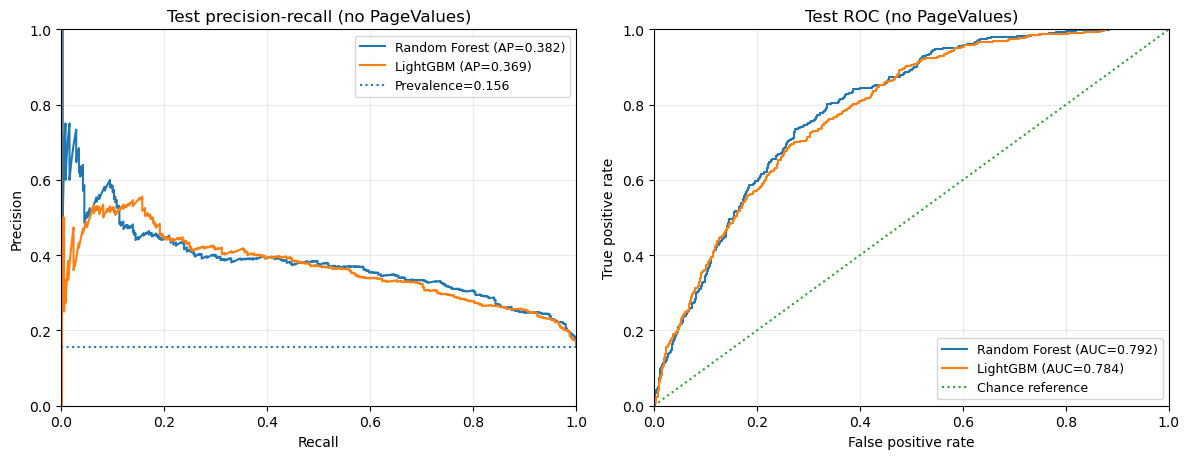

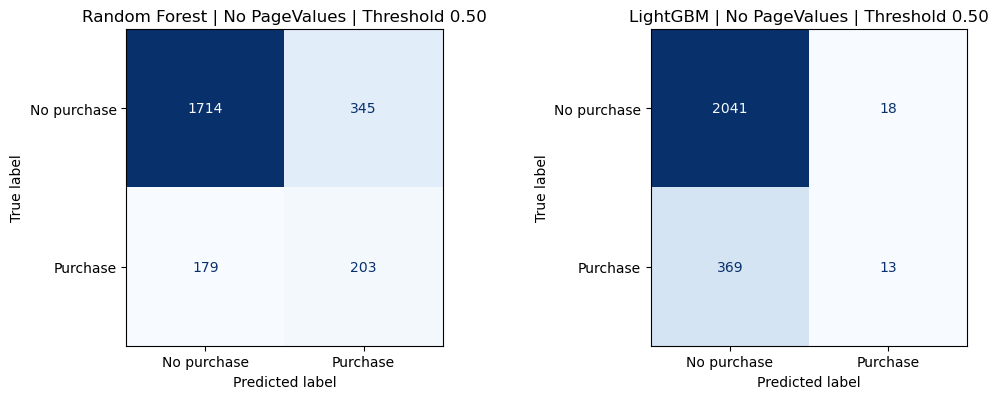

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for algorithm in ("Random Forest", "LightGBM"):
    p = test_predictions[(algorithm, "Excluded")]
    pr, rec, _ = precision_recall_curve(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    ap = average_precision_score(y_test, p)
    ra = roc_auc_score(y_test, p)
    axes[0].plot(rec, pr, label=f"{algorithm} (AP={ap:.3f})")
    axes[1].plot(fpr, tpr, label=f"{algorithm} (AUC={ra:.3f})")
axes[0].axhline(y_test.mean(), linestyle=':', label=f"Prevalence={y_test.mean():.3f}")
axes[1].plot([0,1],[0,1],linestyle=':',label="Chance reference")
axes[0].set(title="Test precision-recall (no PageValues)", xlabel="Recall", ylabel="Precision", xlim=(0,1), ylim=(0,1))
axes[1].set(title="Test ROC (no PageValues)", xlabel="False positive rate", ylabel="True positive rate", xlim=(0,1), ylim=(0,1))
for ax in axes: ax.legend(fontsize=9); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11,4.1))
for ax, algorithm in zip(axes, ("Random Forest", "LightGBM")):
    p = test_predictions[(algorithm, "Excluded")]
    cm = confusion_matrix(y_test, p >= 0.5, labels=[0,1])
    ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(ax=ax, cmap="Blues", values_format='d', colorbar=False)
    ax.set_title(f"{algorithm} | No PageValues | Threshold 0.50")
plt.tight_layout();plt.show()

## 8 | Probability calibration and class-weight caveat

The reliability plot groups predictions into probability bins and compares observed conversion rates with predicted probabilities. It is descriptive, based on the untouched test set after all modeling decisions are fixed. It is **not** used to fit a calibrator or retune the models.

Class weights were candidates in model tuning. A weighted model's `predict_proba` is not automatically calibrated to the operational purchase rate. Future deployment should use a separate training-only calibration procedure and validate calibration again under deployment prevalences. The Brier score complements ranking-oriented AP.

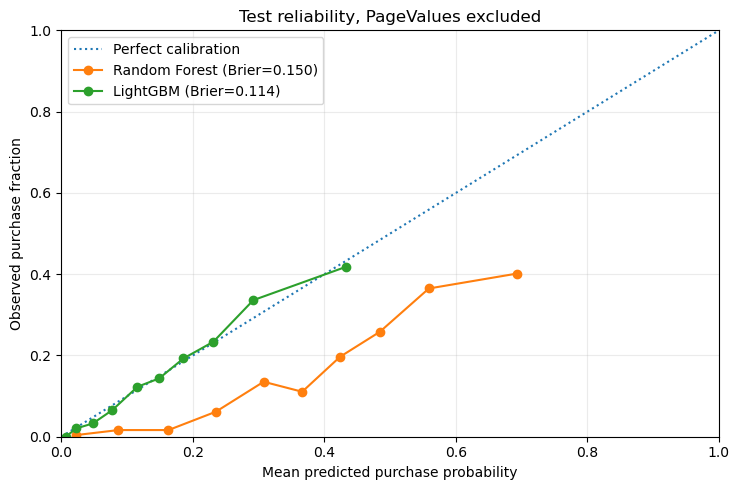

('Random Forest', 'Excluded') selected class weight: balanced_subsample
('LightGBM', 'Excluded') selected class weight: None
('Random Forest', 'Included') selected class weight: balanced_subsample
('LightGBM', 'Included') selected class weight: None


In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot([0, 1], [0, 1], ':', label="Perfect calibration")
for algorithm in ("Random Forest", "LightGBM"):
    p = test_predictions[(algorithm, "Excluded")]
    observed, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=f"{algorithm} (Brier={brier_score_loss(y_test,p):.3f})")
ax.set(title="Test reliability, PageValues excluded", xlabel="Mean predicted purchase probability", ylabel="Observed purchase fraction", xlim=(0,1), ylim=(0,1))
ax.legend(); ax.grid(alpha=0.25); plt.tight_layout();plt.show()

for key, search in searches.items():
    print(key, "selected class weight:", search.best_params_.get("model__class_weight"))

## 9 | PageValues sensitivity

For each algorithm we compare the same fixed test sessions under two complete train-only-tuned pipelines: one excluding `PageValues`, the other including it. The outcome measures **incremental predictive association**, not proof of information leakage, availability at an operational intervention time, or causal contribution.

No model in the main specification uses `PageValues`. Even when inclusion yields higher test AP, additional evidence is required before deploying a model using this feature.

,Model,AP excluded,AP included,AP difference,ROC-AUC excluded,ROC-AUC included,Brier excluded,Brier included
0,Random Forest,0.3816,0.7563,0.3747,0.7923,0.9353,0.1501,0.0814
1,LightGBM,0.3688,0.7685,0.3998,0.7840,0.9371,0.1140,0.0672


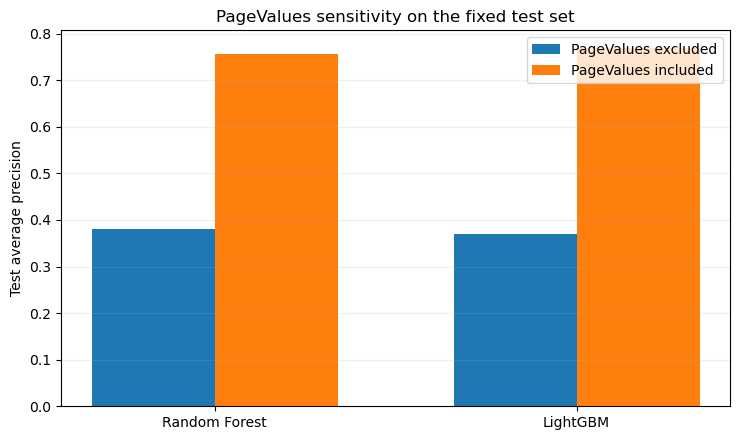

In [9]:
comparison = []
for algorithm in ("Random Forest", "LightGBM"):
    base = test_df[(test_df.Model == algorithm) & (test_df.PageValues == "Excluded") & (test_df.Threshold == 0.5)].iloc[0]
    incl = test_df[(test_df.Model == algorithm) & (test_df.PageValues == "Included") & (test_df.Threshold == 0.5)].iloc[0]
    comparison.append({
        "Model":algorithm,
        "AP excluded":base["AP (PR summary)"], "AP included":incl["AP (PR summary)"],
        "AP difference":incl["AP (PR summary)"] - base["AP (PR summary)"],
        "ROC-AUC excluded":base["ROC-AUC"],"ROC-AUC included":incl["ROC-AUC"],
        "Brier excluded":base["Brier"],"Brier included":incl["Brier"]
    })
sensitivity_df=pd.DataFrame(comparison)
display(sensitivity_df.round(4))

fig, ax=plt.subplots(figsize=(7.5,4.5))
xs=np.arange(2)
width=0.34
ap_no=sensitivity_df["AP excluded"].to_numpy()
ap_yes=sensitivity_df["AP included"].to_numpy()
ax.bar(xs-width/2, ap_no, width, label="PageValues excluded")
ax.bar(xs+width/2, ap_yes, width, label="PageValues included")
ax.set_xticks(xs, sensitivity_df["Model"])
ax.set(ylabel="Test average precision", title="PageValues sensitivity on the fixed test set")
ax.legend(); ax.grid(axis="y",alpha=0.2)
plt.tight_layout();plt.show()

## 10 | Feature importance (training-only held-out folds)

We use **raw-feature permutation importance** on training CV validation folds for the **no-PageValues models**. For each fold, a clone of the selected model is fitted on that fold's training portion; each raw feature is independently permuted in the held-out portion and the change in AP is recorded. This design assesses generalization-oriented importance without using final test labels for feature selection.

Permutation importance: Random Forest
Random Forest top predictors (mean AP decrease):


,Feature,mean_ap_drop,std_across_folds
7,Month,0.0769,0.0314
4,ExitRates,0.0558,0.0152
10,ProductRelated_Duration,0.0541,0.0126
2,BounceRates,0.0278,0.0133
9,ProductRelated,0.0242,0.0099
14,VisitorType,0.0159,0.0075
0,Administrative,0.0136,0.0096
13,TrafficType,0.0108,0.0159
1,Administrative_Duration,0.0081,0.0116
11,Region,0.0057,0.0021


Permutation importance: LightGBM
LightGBM top predictors (mean AP decrease):


,Feature,mean_ap_drop,std_across_folds
4,ExitRates,0.0843,0.0103
7,Month,0.0736,0.0201
10,ProductRelated_Duration,0.0678,0.0008
2,BounceRates,0.0199,0.0037
14,VisitorType,0.0110,0.0063
9,ProductRelated,0.0109,0.0109
1,Administrative_Duration,0.0102,0.0074
0,Administrative,0.0096,0.0039
8,OperatingSystems,0.0046,0.0031
13,TrafficType,0.0043,0.0023


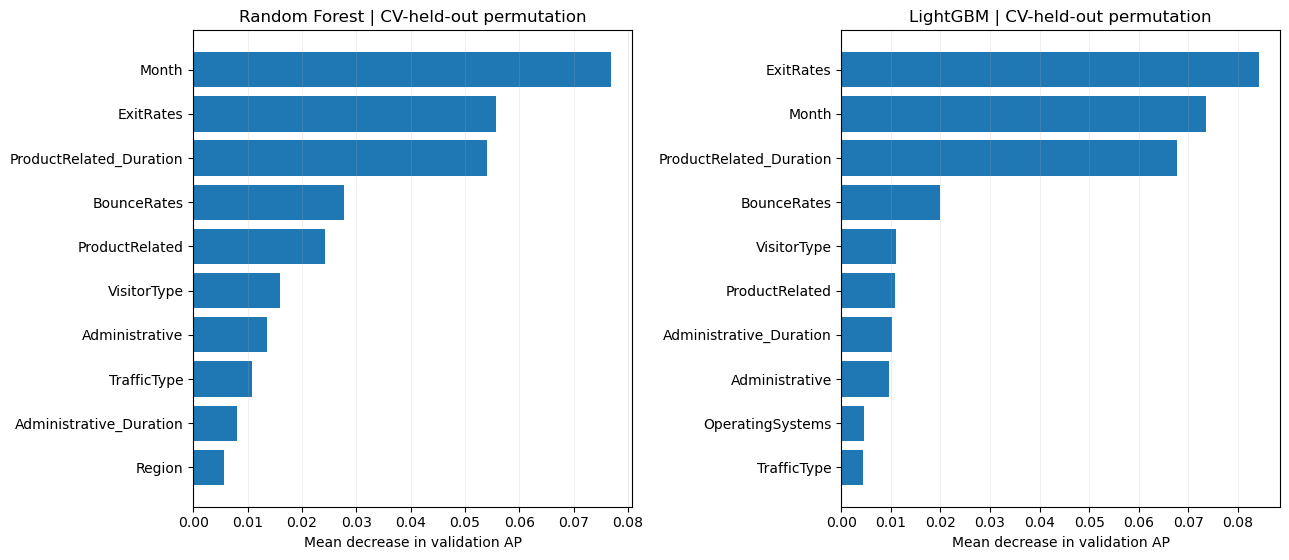

In [10]:
feature_importance_tables = {}
# Two CV folds and 3 permutations per feature keep compute cost reasonable.
folds_for_importance = [0, 1]
for algorithm in ("Random Forest", "LightGBM"):
    feat = FEATURE_SETS["Excluded"]
    estimator = searches[(algorithm, "Excluded")].best_estimator_
    importance_frames=[]
    print("Permutation importance:", algorithm, flush=True)
    for fold_id in folds_for_importance:
        tr_idx, va_idx = cv_splits[fold_id]
        fitted = clone(estimator).fit(X_train_all.iloc[tr_idx][feat], y_train.iloc[tr_idx])
        out = permutation_importance(
            fitted, X_train_all.iloc[va_idx][feat], y_train.iloc[va_idx],
            scoring="average_precision", n_repeats=3,
            random_state=SEED + fold_id, n_jobs=2
        )
        for j, feature in enumerate(feat):
            importance_frames.append({"Feature":feature, "Fold":fold_id+1,
                                      "Importance (AP drop)": float(out.importances_mean[j])})
    imp = (pd.DataFrame(importance_frames).groupby("Feature", as_index=False)
           .agg(mean_ap_drop=("Importance (AP drop)","mean"),
                std_across_folds=("Importance (AP drop)","std"))
           .sort_values("mean_ap_drop",ascending=False))
    feature_importance_tables[algorithm] = imp
    print(algorithm, "top predictors (mean AP decrease):")
    display(imp.head(10).round(4))

fig, axes=plt.subplots(1,2,figsize=(13,5.7))
for ax, algorithm in zip(axes,("Random Forest","LightGBM")):
    top = feature_importance_tables[algorithm].head(10).sort_values("mean_ap_drop")
    ax.barh(top["Feature"],top["mean_ap_drop"])
    ax.set(title=algorithm+" | CV-held-out permutation", xlabel="Mean decrease in validation AP")
    ax.grid(axis="x",alpha=0.2)
plt.tight_layout();plt.show()

## 11 | Exploratory late-month stress test (training data only)

This supplementary robustness analysis **never touches the fixed external test set**. It holds out Oct–Dec observations from the supplied training CSV and fits predeclared baseline RF and LightGBM models using earlier listed months. `Month` itself is removed as a predictor to avoid unseen-category artefacts and `PageValues` remains excluded.

The dataset supplies a `Month` category, **not precise session timestamps**. Therefore this is only a coarse month-grouped stress test, not a verified prospective chronological experiment. The class priors also vary substantially by month, so performance changes cannot be uniquely attributed to time drift. The predeclared model settings are used rather than parameters selected using the late-month labels.

In [11]:
month_order = ["Feb","Mar","May","June","Jul","Aug","Sep","Oct","Nov","Dec"]
early_months = set(month_order[:7])
late_months = set(month_order[7:])
early_mask = train_raw["Month"].isin(early_months)
late_mask = train_raw["Month"].isin(late_months)
assert (early_mask | late_mask).all() and not (early_mask & late_mask).any()
robust_features = [f for f in FEATURE_SETS["Excluded"] if f != "Month"]
print("Earlier train:",int(early_mask.sum()),"purchase prevalence:",round(float(y_train[early_mask].mean()),4))
print("Later validation:",int(late_mask.sum()),"purchase prevalence:",round(float(y_train[late_mask].mean()),4))

stress_models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=14,
                                            min_samples_leaf=3, max_features="sqrt",
                                            random_state=SEED,n_jobs=1),
    "LightGBM": LGBMClassifier(n_estimators=250, learning_rate=.05,
                               num_leaves=15, min_child_samples=30,
                               random_state=SEED, verbosity=-1,n_jobs=1,
                               deterministic=True,force_col_wise=True)
}
robust_rows = []
for algorithm, mod in stress_models.items():
    pipe = Pipeline([("preprocessor",make_preprocessor(robust_features)),("model",mod)])
    pipe.fit(X_train_all.loc[early_mask,robust_features],y_train[early_mask])
    pred_prob = pipe.predict_proba(X_train_all.loc[late_mask,robust_features])[:,1]
    scores=metric_row(algorithm,"Excluded; Month omitted",y_train[late_mask],pred_prob)
    robust_rows.append(scores)
print("Exploratory late-month validation, predeclared configurations:")
display(pd.DataFrame(robust_rows)[cols].round(4))

Earlier train: 5578 purchase prevalence: 0.1156
Later validation: 4186 purchase prevalence: 0.2105
Exploratory late-month validation, predeclared configurations:


,Model,PageValues,Threshold,AP (PR summary),ROC-AUC,Recall,Precision,F1,Accuracy,Balanced accuracy,Brier
0,Random Forest,Excluded; Month omitted,0.5,0.3362,0.6934,0.0238,0.3962,0.0450,0.7869,0.5071,0.1594
1,LightGBM,Excluded; Month omitted,0.5,0.3252,0.6734,0.0465,0.4184,0.0838,0.7857,0.5146,0.1642


## 12 | Core deliverables
Using the shared untouched test set of 2,441 online sessions (15.6% purchases), Random Forest attained AP=0.3816 and ROC-AUC=0.7923, while LightGBM attained AP=0.3688 and ROC-AUC=0.7840, with PageValues excluded. The higher observed test AP was achieved by Random Forest. At threshold 0.50, purchase recall was 0.531 for Random Forest and 0.034 for LightGBM. These are descriptive single-split results, not evidence that small differences necessarily generalize to new samples.
Adding PageValues to Random Forest changed held-out AP by +0.3747 under independently tuned training-only pipelines. This change alone cannot establish target leakage.
Adding PageValues to LightGBM changed held-out AP by +0.3998 under independently tuned training-only pipelines. This change alone cannot establish target leakage.
Brier scores and reliability plots should be inspected before any business threshold decision, particularly where class weights are used. Permutation importance measures predictive reliance, not causal effects, and feature availability must be confirmed at the intended intervention time.

- **RF and LightGBM:** train-only CV hyperparameter selection, model fit, and untouched test metrics.
- **Main results:** PageValues excluded, positive class = `Revenue=True`, test AP primary; ROC-AUC, recall, precision, F1, accuracy, balanced accuracy and Brier as additional measures.
- **Sensitivity:** same two models including PageValues, with separate train-only tuning. Compare changes without claiming definitive target leakage.
- **Interpretation:** validation-fold permutation importance of raw columns, and exploratory month-grouped robustness diagnostic.
- **Calibration caution:** class-weighted learners can give biased purchase probabilities; test reliability is diagnostic and no test-based refitting was performed.